# Universidad Tecnológica de Panamá

## Facultad de Ingeniería de Sistemas Computacionales

Departamento de Computación y Simulación de Sistemas  
Licenciatura en Ingeniería de Software

### Ingeniería Ambiental

### Proyecto Final

**Análisis de la sensibilidad del consumo energético ante fluctuaciones microclimáticas y eventos de temperatura regional**

**EnerClima Panamá**

**Integrantes:** Alejandro Muñoz, Angie Valdés, Richard Smith y Abisai Bellamy  
**Grupo:** 1SF132  
**Profesora:** Vivian Valenzuela  
**Año:** 2026

Conservamos el título académico original y usamos EnerClima Panamá como nombre de nuestra plataforma.

## Introducción

En este proyecto estudiamos cómo las condiciones meteorológicas observadas en tres ciudades se relacionan con la demanda eléctrica nacional de Panamá. Organizamos los datos, describimos los patrones históricos, comparamos modelos y presentamos los hallazgos en una herramienta web.

## Planteamiento del problema

La demanda puede variar por hora, calendario y clima. La serie disponible corresponde a Panamá a nivel nacional, por lo que no podemos atribuir consumos a Tocumen, Santiago o David. Investigamos cuánto aporta la temperatura local a la descripción y estimación de la demanda nacional por hora.

## Justificación ambiental

Analizamos esta relación para entender cómo las temperaturas altas pueden coincidir con exigencias distintas sobre el sistema eléctrico. La planificación energética requiere evidencia sobre la demanda y el clima, pero distinguimos los antecedentes internacionales de los resultados que medimos en este conjunto nacional.

## Objetivo general

Evaluamos la sensibilidad descriptiva y predictiva de la demanda eléctrica nacional ante variaciones de temperatura registradas en Tocumen, Santiago y David.

## Objetivos específicos

- Revisamos la integridad temporal, los rangos y las unidades de los datos.
- Describimos la demanda, las variables meteorológicas y las horas de temperatura elevada.
- Comparamos modelos mediante particiones cronológicas.
- Estimamos asociaciones ajustadas y escenarios de sensibilidad condicionados al modelo.
- Documentamos los límites para evitar conclusiones causales o regionales.

## Preguntas de investigación

- ¿Cómo varía la demanda media durante horas sobre el percentil 95 de temperatura de cada estación?
- ¿Cómo se asocian las temperaturas de Tocumen, Santiago y David con la demanda nacional después de ajustar por calendario?
- ¿Cuánto mejora la estimación al incorporar el historial reciente de demanda?
- ¿Qué cambios calcula el modelo al perturbar la temperatura dentro del rango observado?

## Descripción del conjunto de datos

Analizamos 48,048 registros horarios y 17 variables: fecha, demanda nacional, cuatro variables meteorológicas para cada estación y tres indicadores de calendario. El archivo de pronóstico semanal contiene 40,152 registros. La demanda está expresada en MWh por intervalo horario según la ficha incluida en el paquete.

## Alcance y limitaciones

Usamos datos históricos de 2015 a 2020. La predicción principal utiliza clima observado en la misma hora objetivo y por tanto es retrospectiva. Las asociaciones no prueban causalidad, los escenarios no son proyecciones climáticas y la demanda es nacional. Conservamos seis valores bajos para que se revisen con la fuente.

## Índice del cuaderno

1. Preparación del entorno.
2. Auditoría y cobertura de los datos.
3. Modelos y resultados de prueba.
4. Eventos térmicos y asociaciones ajustadas.
5. Escenarios de sensibilidad.
6. Figuras, interpretación y fuentes.

## 1. Preparación del entorno

Usamos rutas relativas derivadas de la ubicación de este cuaderno. En una instalación nueva, instalamos las dependencias declaradas en `requirements.txt`.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "notebooks":
    PROJECT_ROOT = NOTEBOOK_DIR.parent
elif (NOTEBOOK_DIR / "scripts" / "run_analysis.py").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
else:
    raise FileNotFoundError("Abrimos este cuaderno desde notebooks/ o desde la carpeta del proyecto.")

if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")])

sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
print(f"Proyecto: {PROJECT_ROOT.name}")
print(f"Archivo de datos: {(PROJECT_ROOT / 'data/raw/continuous dataset.csv').exists()}")

Proyecto: EnerClima-Panama
Archivo de datos disponible: True


Al mantener las rutas relativas, podemos ejecutar el análisis desde Windows, Linux o Google Colab si conservamos la carpeta del proyecto y colocamos los datos en `data/raw/`.

## 2. Auditoría y análisis reproducible

Ejecutamos la canalización completa. La auditoría comprueba continuidad horaria, duplicados, valores ausentes y rangos; el análisis produce estadísticas, asociaciones ajustadas, modelos, eventos térmicos y escenarios de sensibilidad.

In [2]:
analysis_script = PROJECT_ROOT / "scripts" / "run_analysis.py"
subprocess.check_call([sys.executable, str(analysis_script)], cwd=PROJECT_ROOT)

0

## 3. Calidad y cobertura de los datos

In [3]:
import pandas as pd

audit = json.loads((PROJECT_ROOT / "results/metrics/auditoria.json").read_text(encoding="utf-8"))
quality = pd.DataFrame(
    {
        "Indicador": ["Filas", "Horas faltantes", "Fechas duplicadas", "Valores nulos", "Valores infinitos"],
        "Resultado": [audit["filas"], audit["horas_faltantes"], audit["fechas_duplicadas"], audit["valores_nulos"], audit["valores_infinitos"]],
    }
)
display(quality)
print(f"Periodo: {audit['fecha_inicio']} a {audit['fecha_fin']}")
print(f"Cobertura de pronóstico semanal en el histórico: {audit['forecast_cobertura_pct']:.2f}%")

,Indicador,Resultado
0,Filas,48048
1,Horas faltantes,0
2,Fechas duplicadas,0
3,Valores nulos,0
4,Valores infinitos,0


Periodo: 2015-01-03T01:00:00 a 2020-06-27T00:00:00
Cobertura de pronóstico semanal en el histórico: 97.91%


La secuencia conserva sus 48,048 horas sin vacíos, duplicados ni datos nulos. Encontramos seis demandas inferiores a 500 MWh que requieren confirmación externa y las retenemos sin imputarlas ni borrarlas.

Conservamos seis valores muy bajos de demanda observados el 20 de enero de 2019 entre las 12:00 y las 17:00. Los señalamos como posibles anomalías para revisión con la fuente, sin corregirlos ni eliminarlos.

## 4. Resultados principales

In [4]:
results = json.loads((PROJECT_ROOT / "results/metrics/resultados.json").read_text(encoding="utf-8"))
models = pd.DataFrame(results["modelos_prueba"])
models = models.rename(columns={"modelo": "Modelo", "mae": "MAE", "rmse": "RMSE", "mape_pct": "MAPE (%)", "r2": "R²"})
display(models.round(3))
selected = models.loc[models["Modelo"] == results["particion"]["modelo_seleccionado"]].iloc[0]
print(f"Partición temporal de prueba: {results['particion']['inicio_prueba']} a {results['particion']['fin_prueba']}")
print(f"Modelo seleccionado en validación: {selected['Modelo']}")
print("El pronóstico semanal de predespacho se evalúa aparte en las 14 semanas oficiales.")

,Modelo,MAE,RMSE,MAPE (%),R²
0,random_forest_temporal_clima_historia,19.613,27.723,1.663,0.977
1,regresion_temporal_clima_historia,29.407,38.328,2.485,0.957
2,referencia_semanal_ingenua,71.274,99.229,5.946,0.711
3,regresion_temporal_clima,119.127,147.291,10.035,0.364
4,regresion_temporal,124.728,153.124,10.449,0.312


Partición temporal de prueba: 2019-09-01T19:00:00 a 2020-06-27T00:00:00
Modelo seleccionado en validación: random_forest_temporal_clima_historia
El pronóstico semanal de predespacho se evalúa aparte en las 14 semanas oficiales.


El modelo con historia, clima y calendario presenta el menor error de prueba entre los modelos comparados. Interpretamos su desempeño con cautela porque la evaluación usa meteorología observada en la hora que estima.

## 5. Eventos de temperatura alta y asociaciones

Definimos evento térmico como una hora por encima del percentil 95 histórico de temperatura de cada estación. Las diferencias de demanda entre horas de evento y el resto son descriptivas. El modelo de regresión ajustada incluye calendario y las tres temperaturas simultáneamente, con errores HAC de 24 rezagos horarios; no representa un efecto causal.

In [5]:
events = pd.DataFrame(results["eventos"])
display(events[["estacion", "percentil_95_c", "horas_sobre_umbral", "demanda_media_eventos_mwh", "demanda_media_resto_mwh", "diferencia_media_mwh"]].round(2))
associations = pd.DataFrame(results["asociaciones_ajustadas"])
display(associations[["estacion", "coeficiente_mwh_por_c", "ic95_inferior", "ic95_superior", "p_valor"]].round(3))

,estacion,percentil_95_c,horas_sobre_umbral,demanda_media_eventos_mwh,demanda_media_resto_mwh,diferencia_media_mwh
0,Tocumen,30.41,2403,1372.69,1172.88,199.81
1,Santiago,33.07,2403,1370.21,1173.01,197.20
2,David,29.48,2403,1373.65,1172.82,200.83


,estacion,coeficiente_mwh_por_c,ic95_inferior,ic95_superior,p_valor
0,Tocumen,22.720,18.328,27.111,0.000
1,Santiago,-4.370,-7.632,-1.109,0.009
2,David,5.285,1.127,9.444,0.013


Las diferencias sobre el percentil 95 son descriptivas. Los coeficientes ajustados cambian entre estaciones; por sus correlaciones y el alcance nacional, no los interpretamos como efectos causales o consumos locales.

## 6. Sensibilidad simulada del modelo

In [6]:
scenarios = pd.read_csv(PROJECT_ROOT / "results/tables/escenarios_sensibilidad.csv") if (PROJECT_ROOT / "results/tables/escenarios_sensibilidad.csv").exists() else pd.DataFrame(results["sensibilidad"])
display(scenarios[["estacion", "incremento_c", "cambio_estimado_mwh", "cambio_estimado_pct", "referencias_validas"]].round(3))
print("Interpretamos estos cambios como respuesta condicionada al modelo y a las variables observadas, no como predicción causal.")

,estacion,incremento_c,cambio_estimado_mwh,cambio_estimado_pct,referencias_validas
0,Tocumen,1,0.439,0.037,6921
1,Tocumen,2,0.661,0.056,6337
2,Tocumen,3,0.709,0.061,5451
3,Santiago,1,0.207,0.017,7027
4,Santiago,2,0.381,0.032,6913
5,Santiago,3,0.487,0.041,6771
6,David,1,0.287,0.024,7003
7,David,2,0.446,0.037,6843
8,David,3,0.421,0.035,6627
9,Tres estaciones,1,0.967,0.081,6833


Interpretamos estos cambios como respuesta condicionada al modelo y a las variables observadas, no como predicción causal.


Cuando aumentamos simultáneamente la temperatura en las tres estaciones en 1 °C, el cambio medio calculado es cercano a 0.97 MWh por intervalo. Este escenario mantiene fijos los demás predictores y representa la respuesta del Random Forest dentro de los casos válidos.

## 7. Figuras generadas por la canalización

perfil_horario.png


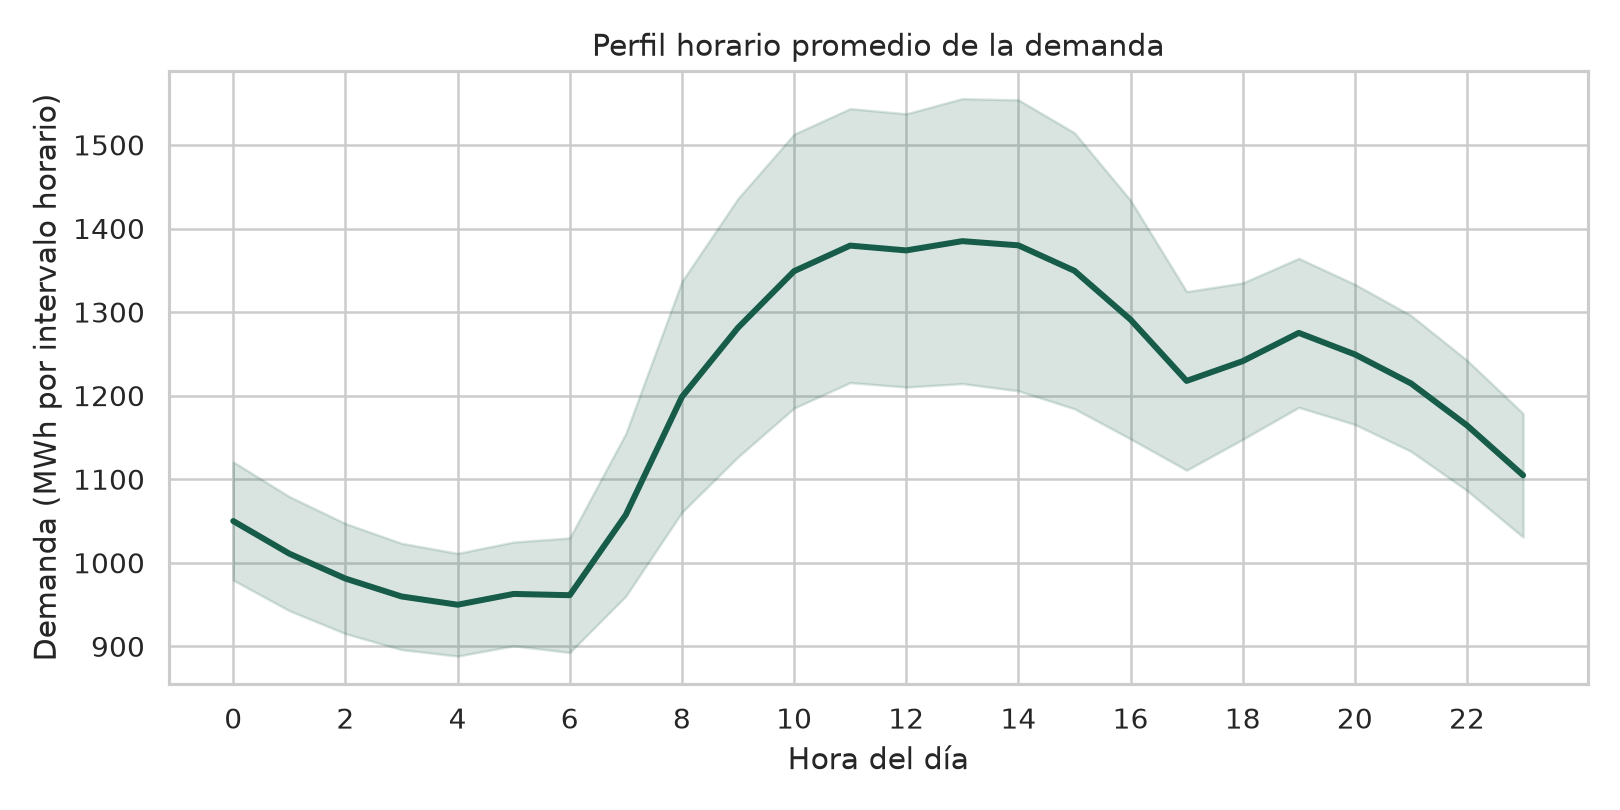

temperatura_demanda.png


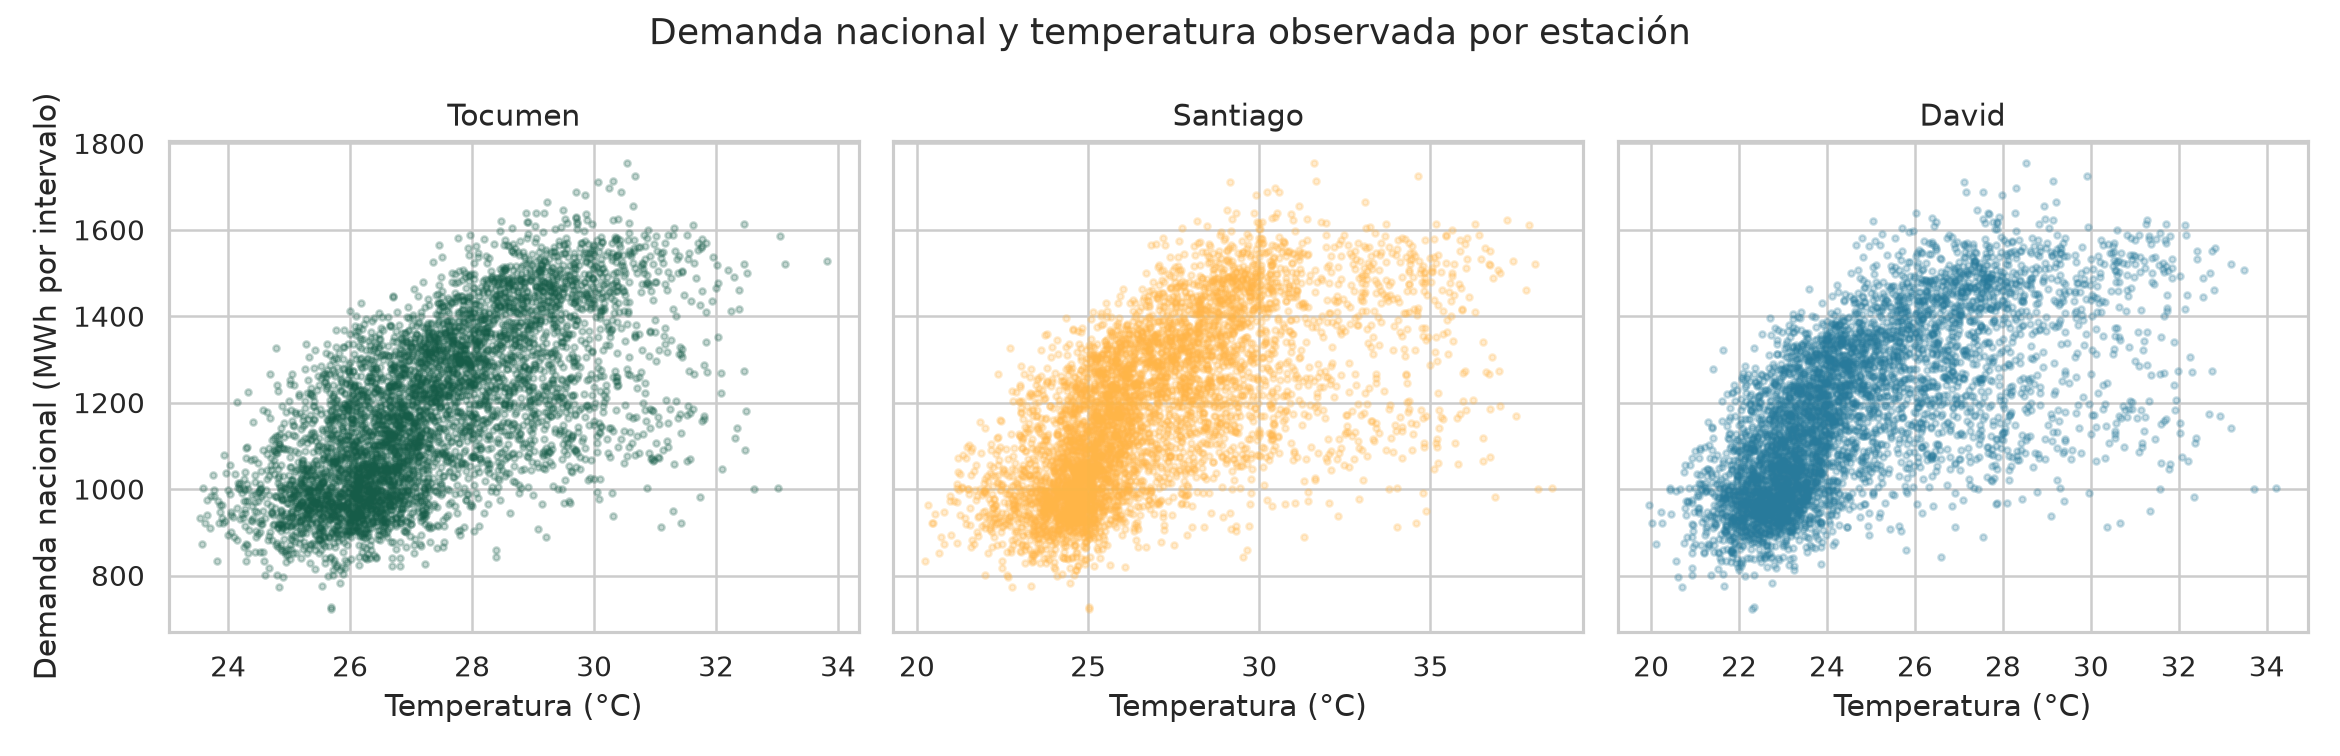

sensibilidad_temperatura.png


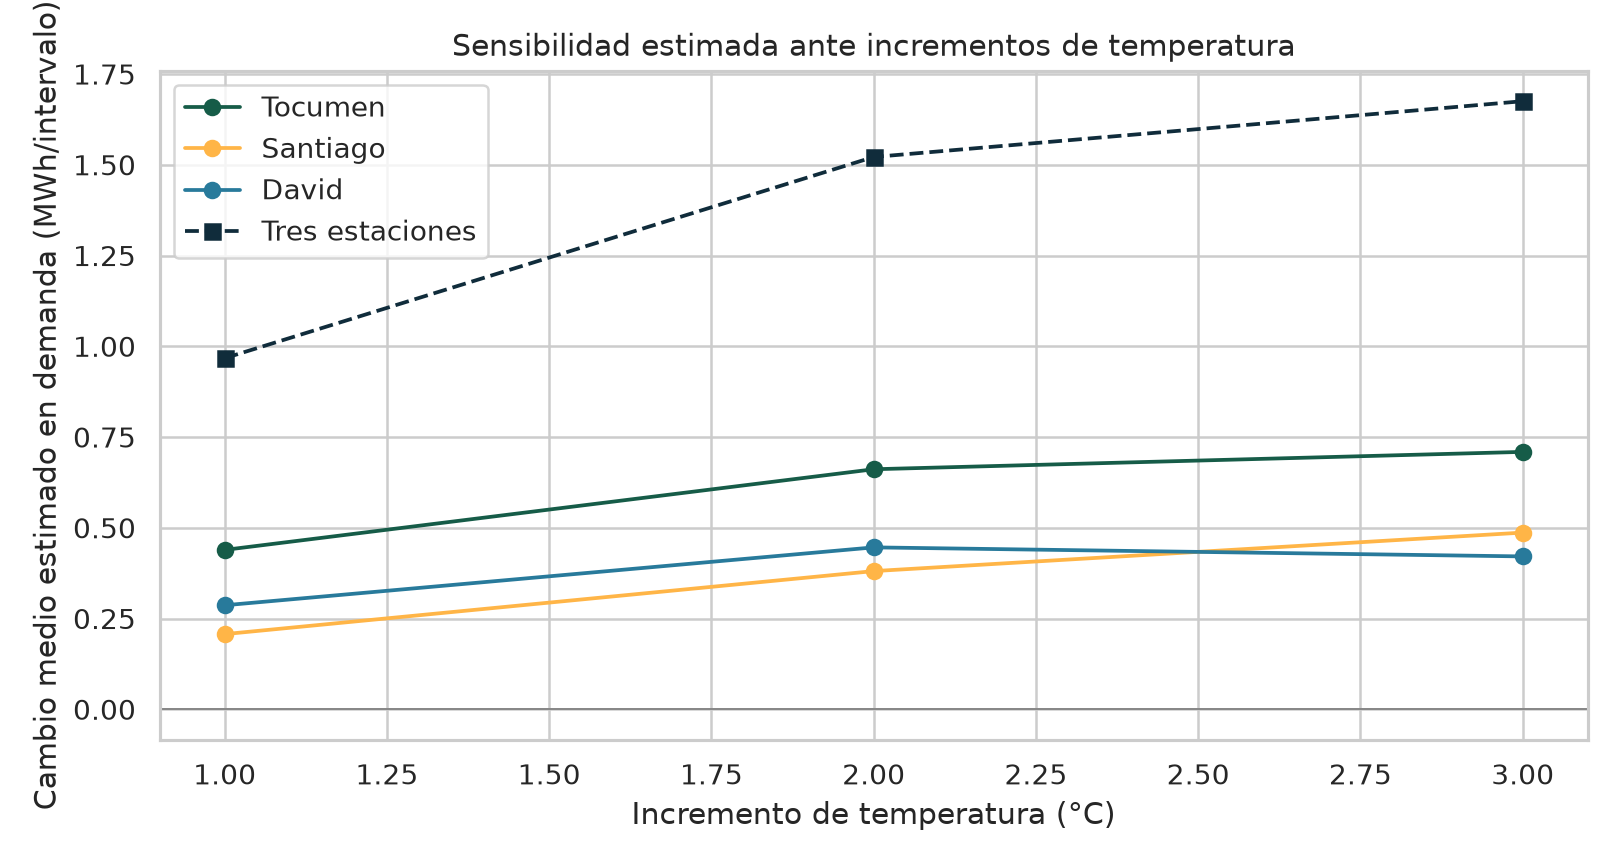

In [7]:
from IPython.display import Image, display

for figure_name in ["perfil_horario.png", "temperatura_demanda.png", "sensibilidad_temperatura.png"]:
    figure_path = PROJECT_ROOT / "results" / "figures" / figure_name
    if figure_path.exists():
        print(figure_name)
        display(Image(filename=str(figure_path)))

Las figuras resumen los perfiles horarios, las asociaciones y las perturbaciones. Las interpretamos junto con las tablas y mantenemos visibles las unidades y las limitaciones del conjunto.

## 8. Interpretación y límites

Observamos que el modelo con historia horaria, calendario y clima tiene menor error que las referencias de prueba dentro de esta partición temporal. La sensibilidad simulada es pequeña y escalonada, comportamiento compatible con un modelo de árboles. Las temperaturas pueden estar correlacionadas entre estaciones y con la hora del día.

Las variables meteorológicas de la misma hora del objetivo permiten un análisis retrospectivo, no una predicción operativa con clima futuro. El conjunto es nacional para demanda y contiene puntos meteorológicos locales; no inferimos consumo regional. También documentamos la discrepancia de unidades de QV2M en el archivo de metadatos y evitamos convertirla.

## 9. Fuentes y reproducibilidad

Usamos el conjunto de pronóstico de carga a corto plazo de Panamá distribuido por IEEE PES Data Sharing Task Force, junto con los metadatos proporcionados con el paquete. Contrastamos los códigos meteorológicos con documentación de NASA POWER y MERRA-2.

La canalización y los datos de entrada permanecen bajo rutas relativas. Para repetir el análisis, ejecutamos este cuaderno en orden o usamos `python scripts/run_analysis.py` desde la carpeta principal. Las fuentes completas se encuentran en `docs/references/referencias_verificadas.md`.